In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
df = pd.read_csv('/kaggle/input/datasets/mirichoi0218/insurance/insurance.csv')

In [3]:
print(df.shape)          # (rows, columns)
print(df.dtypes)         # data types of each column
print(df.head())         # first 5 rows
print(df.describe())     # count, mean, std, min, Q1, Q2, Q3, max

(1338, 7)
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.0

In [4]:
col = df['charges']

mean_val = col.mean()
trimmed_mean = stats.trim_mean(col.dropna(), proportiontocut=0.1)
median_val = col.median()
mode_val = col.mode()[0]

print(f'Mean: {mean_val:,.0f}')
print(f'Trimmed Mean: {trimmed_mean:,.0f}')
print(f'Median: {median_val:,.0f}')
print(f'Mode: {mode_val:,.0f}')

Mean: 13,270
Trimmed Mean: 11,076
Median: 9,382
Mode: 1,640


In [5]:
variance_val = col.var()      # sample variance (ddof=1 by default)
std_val = col.std()

mad_val = (col - col.mean()).abs().mean()   # Mean Absolute Deviation

iqr_val = col.quantile(0.75) - col.quantile(0.25)

print(f'Variance: {variance_val:,.2f}')
print(f'Std Dev: {std_val:,.2f}')
print(f'MAD: {mad_val:,.2f}')
print(f'IQR: {iqr_val:,.2f}')

Variance: 146,652,372.15
Std Dev: 12,110.01
MAD: 9,091.13
IQR: 11,899.63


In [6]:
print(f'Skewness: {col.skew():.4f}')
print(f'Kurtosis: {col.kurt():.4f}')   # excess kurtosis

# IQR-based outlier detection
Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

outliers = col[(col < lower_fence) | (col > upper_fence)]

print(f'Number of outliers: {len(outliers)}')
print(outliers)

Skewness: 1.5159
Kurtosis: 1.6063
Number of outliers: 139
14      39611.75770
19      36837.46700
23      37701.87680
29      38711.00000
30      35585.57600
           ...     
1300    62592.87309
1301    46718.16325
1303    37829.72420
1313    36397.57600
1323    43896.37630
Name: charges, Length: 139, dtype: float64


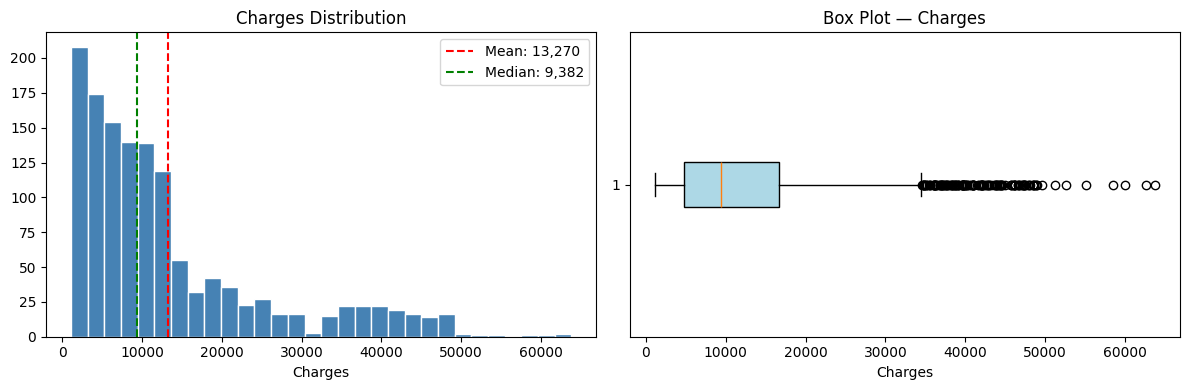

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
axes[0].hist(col.dropna(), bins=30, color='steelblue', edgecolor='white')
axes[0].axvline(mean_val, color='red', linestyle='--',
                label=f'Mean: {mean_val:,.0f}')
axes[0].axvline(median_val, color='green', linestyle='--',
                label=f'Median: {median_val:,.0f}')

axes[0].set_title('Charges Distribution')
axes[0].set_xlabel('Charges')
axes[0].legend()

# Box plot
axes[1].boxplot(
    col.dropna(),
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue')
)

axes[1].set_title('Box Plot — Charges')
axes[1].set_xlabel('Charges')

plt.tight_layout()
plt.show()